# Orbital Elements Representation

The discussion of orbital mechanics up to now has been confined to two dimensions, i.e., to the plane of the orbits themselves. This chapter explores the means of describing orbits in three-dimensional space, which, of course, is the setting for real missions and orbital maneuvers.


## State Vector
We know that the equation of motion of a satellite orbiting around the Earth is

$$\ddot{\overrightarrow{r}}=-\frac{\mu }{r^{3}}\overrightarrow{r}$$

, where the position vector $r$ is defined a relative to an **inertial reference system**. A reference system is said to be inertial if it does not rotate or accelerate relative to the distant universe; these systems allow us to apply Newton's laws of motion without adding "fictitious" forces like centrifugal or Coriolis effects. The most popular inertial reference systems are:

- **J2000**: Defined by the Earth's orientation at specific instant in time (January 1st, 2000 at 12 p.m. terrestrial time). The principal plane is the Earth Mean Equator at J200 epoch, while the $X$ axis points toward the **vernal equinox** (the intersection between the ecliptic and the celestial equator)

- **ICRF**: Instead of referring to any Earth's based marker, this reference systems uses quasars (extragalactic radio sources) to define a truly stable system. It has been designed to be as close as possible to J2000, but without being related to the Earth's spin axis precession and nutation.


Another commonly used inertial coordinate system is the **geocentric equatorial frame**. Also in this case the $\widehat{I}$ axis points in the vernal equinox direction. The $\widehat{I}\widehat{J}$ plane is the Earth’s equatorial plane, and the $\widehat{K}$ axis coincides with the Earth’s axis of rotation and points northward. The unit vectors $\widehat{I}$, $\widehat{J}$ and $\widehat{K}$ form a right-handed triad.
The non-rotating geocentric equatorial frame serves as an inertial frame for the two-body problem, even if is not truly an inertial frame since the center of the Earth is always accelerating towards  the Sun and the Moon, a fact which we ignore in the two-body formulation.

<center><img src="Images/geocentriEqRefSystem.png" alt="Drawing" style="width: 600px;"/><center>




We define the **state vector** as the 6-dimension vector containing the position and the velocity components of the satellite respect to the reference system. In the geocentric equatorial frame the state vector is given in components form by:

$$\begin{matrix}
 \overrightarrow{r} = x\widehat{I} + y\widehat{J} + z\widehat{K}  \\
 \overrightarrow{\dot{r}} = \dot{x}\widehat{I} + \dot{y}\widehat{J} + \dot{z}\widehat{K}
\end{matrix}$$



Here below the state vector and its time derivative are reported:
$$ \left \{ \begin{matrix}
x\\ 
y\\ 
z\\ 
\dot{x}\\ 
\dot{y}\\ 
\dot{z}
\end{matrix} \right \},
\left \{ \begin{matrix}
\dot{x}\\ 
\dot{y}\\ 
\dot{z}\\ 
-\frac{\mu }{r^{3}}x\\ 
-\frac{\mu }{r^{3}}y\\ 
-\frac{\mu }{r^{3}}z
\end{matrix} \right \}$$

### Numerical integration of the state vector
The knowledge of the initial state vector and how it changes over time allows us to numerically integrate the equation of motion. We can derive the following system of differential equations:

$$\ddot{x}=-\frac{\mu }{(x^{3}+y^{3}+z^{3})^{3/2}}x$$
$$\ddot{y}=-\frac{\mu }{(x^{3}+y^{3}+z^{3})^{3/2}}y$$
$$\ddot{z}=-\frac{\mu }{(x^{3}+y^{3}+z^{3})^{3/2}}z$$

These equations can be used with a numerical integrator to solve for the motion of a spacecraft around a planet, moon, star, etc. 

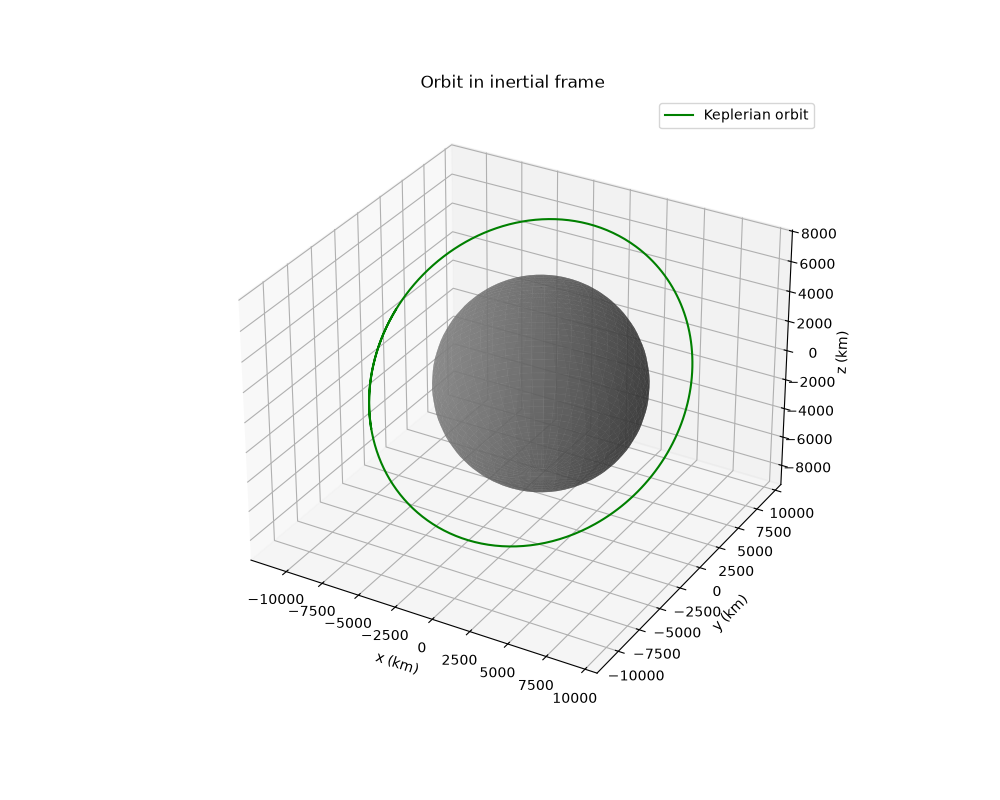

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from routines import *
from astrodynamics import *
%matplotlib widget

init_state = np.array([-10814.629891, 1348.389725, 1348.389725, -1.111477, -4.004645, -4.004645])  # state vector (km, km/sec)

plot_two_body_orbit(init_state, 11500, 500, 'Earth')

## Keplerian Elements

Even if the state vector is enough to derive the orbit using numerical propagation, the simplest way to understand the cheracteristics of the orbit under consideration is using a set of elements that are more descriptive and easy to understand.
The most used set is the **Keplerian (or Classical) elements** one, which is derived starting from the equation of motion and its integrals (angular momentum **$\overrightarrow{h}$**, eccentricity vector **$\overrightarrow{e}$**, and orbital energy **$\varepsilon$**).

The figures below show and explain how the Keplerian elements are defined.
<center><img src="Images/keplerianElems.png" alt="Drawing" style="width: 600px;"/><center>
&nbsp;  
    
<center><img src="Images/keplerianElemsDes.png" alt="Drawing" style="width: 600px;"/><center>


### Degenerate orbits
There are two particular cases where some of the angular elements become undefined:
- $𝒆=0$ (circular orbits) -> $\omega$ and $\theta$ are not defined. 
- $𝒊=0$ (equatorial orbits) -> $\Omega$ and $\omega$ are not defined. 


For circular orbits we define the **argument of latitude** as

 $$ u= \omega + \theta $$

For equatorial orbits we define the **longitude of periapsis** as

 $$ \widetilde{\omega}= \Omega + \omega $$

<center><img src="Images/degenerateOrbits.png" alt="Drawing" style="width: 1100px;"/><center>



Note that the longitude of periapsis is a compound angle, with part of it being measured in the plane of reference and the rest being measured in the plane of the orbit.

## Orbital position as a function of time

The orbit equation defines the path of $m_{2}$ around $m_{1}$:

 $$r=\frac{p}{1 + e\cos \theta}=\frac{h^{2}}{\mu}\frac{1}{1 + e\cos \theta}$$

In this equation, time doesn't appear. The only time-related thing we know up to now is the orbit period, which is a function of the semimajor axis. For many practical reasons we need to derive the position of $m_{2}$ as function of time, which means to be able to calculate the time required to fly between any two true anomalies. By properly time-deriving and manipulating the orbit equation, we get:

 $$t=\frac{h^{3}}{\mu^{2}}\int_{0}^{\theta}\frac{d\theta}{(1+e\cos \theta)^{2}}$$

When $e=0$ (circular orbits), we have:

 $$t=\frac{h^{3}}{\mu^{2}}\theta\mapsto  \theta=\frac{2\pi}{T}t$$
so, the true anomaly is in direct relationship with time. We also define the **mean motion $n$** as the angular speed required for a body running a circular orbit to complete one orbit in the same time of the generic, elliptical orbit:

 $$\boxed{n= \frac{2\pi}{T}=\sqrt{\frac{\mu}{a^3}}}$$



### Mean and Eccentric anomalies

For elliptical orbits, the solution of the above integral is a rather complicated function of the true anomaly. For an elliptical orbit the angular speed of the spacecraft is a function of the true anomaly. This is a result of Kepler’s second law, that equal areas are swept in equal times: the spacecraft must move faster near periapsis and slower near apoapsis to sweep the same area in a given time interval. Thus, the rate of change of the true anomaly is not constant. Here we define two additional anomalies:

The **mean anomaly** $M_e$ for an ellipse is the azimuth position (in radians) of a fictitious body moving around the ellipse at the constant angular speed, i.e. a constant rate that gives the same period as the true anomaly. If we draw a circle that touches the ellipse at periapsis and apoapsis, then the rate of change of the mean anomaly is the rate at which a point must move around this circle to meet the spacecraft at periapsis and apoapsis.

It is function of the true anomaly $\theta$ and eccentricity $e$ and is defined as:

 $$M_e = 2\tan^{-1}\left(\sqrt{\frac{1 - e}{1 + e}}\tan\frac{\theta}{2}\right)-\frac{e\sqrt{1 - e^2}\sin \theta}{1 + e \cos \theta}$$

The mean anomaly is a monotonically increasing function of the true anomaly:

<center><img src="Images/trueVsMeanAnomaly.png" alt="Drawing" style="width: 600px;"/><center>




If we know the orbit period, the equation for the mean anomaly becomes:

 $$\boxed{M_e = \frac{2\pi}{T}t}$$

The **eccentric anomaly** $E$ is defined slightly differently. Imagine the same circle that touches the ellipse at periapsis and apoapsis. Now draw a line perpendicular to the semimajor axis from the orbit to the circle, at the current true anomaly. The angle to the point Q defined in this way on the circle is the eccentric anomaly.

<center><img src="Images/eccentricAnomaly.png" alt="Drawing" style="width: 500px;"/><center>

&nbsp;  



In [5]:
from IPython.display import HTML
HTML(f"""
<div style="display: flex; justify-content: center;">
    <video width="700" height="500" controls>
        <source src="Images/anomalies.mp4" type="video/mp4">
    </video>
</div>
""")


The eccentric anomaly and the true anomaly are related each other by the following equation:

 $$\tan\frac{E}{2} = \sqrt{\frac{1 - e}{1 + e}}\tan\frac{\theta}{2}$$

And finally, the mean anomaly and the eccentric anomaly are related each other by the **Kepler's equation**:

 $$M_e = E - e \sin E$$

This last equation is trascendental, so it cannot be solved analytically. Normally, the Newton's method is used to solve the Kepler's equation.

**- Example 1: Given true anomaly, find time since periapsis:**


In [4]:
#############################
### define the input data ###
theta = 38.943     # true anomaly (deg)
period = 5400   # orbit period (sec)
e = 0.25
#############################

# find the eccentric anomaly as funcion of the true anomaly
E = 2 * np.arctan(math.sqrt((1-e)/(1+e))*np.tan((theta/2)*math.pi/180))

# find the mean anomaly from the Kepler's equation
M_e = E - e*math.sin(E)

# find the time from the mean anomaly
t = (M_e/(2*math.pi))*period

print('When the true anomaly is = ' + str(theta) + ' deg, the relevant time since periapsis is ' + str(t) + ' sec')

When the true anomaly is = 38.943 deg, the relevant time since periapsis is 349.9998790303154 sec


**- Example 2: Given time since periapsis, find the true anomaly:**


In [6]:
#############################
### define the input data ###
t = 350      # time since periapsis (sec)
period = 5400 # orbit period (sec)
e = 0.25
#############################

# find the mean anomaly
M_e = (2*math.pi/period)*t  # rad

# find the eccentric anomaly from the Kepler's equation
E = solve_kepler(e, M_e)

# find the true anomaly
theta = 2 * np.arctan(math.sqrt((1+e)/(1-e))*np.tan(E/2))
if theta < 0:
    theta = theta + 2*math.pi

print('True anomaly at t = ' + str(t) + ' sec is ' + str(math.degrees(theta)) + ' deg')

True anomaly at t = 350 sec is 38.94301267532656 deg


### Mean Longitude

We define **mean longitude** the angular distance the body would have from the reference direction if it moved with uniform speed: $ L = \Omega +\omega+M_e $
 

&nbsp;  

<center><img src="Images/meanLongitude.png" alt="Drawing" style="width: 400px;"/><center>



Note that mean longitude, like mean anomaly, does not measure an angle between any physical objects. It is simply a convenient uniform measure of how far around its orbit a body has progressed since passing the reference direction. 

## Equinoctial Elements

The **equinoctial orbital elements** are a set of six non-singular parameters used in celestial mechanics to avoid the singularities found in Keplerian elements (like argument of periapsis $\omega$ or right ascension of ascending node $\Omega$).


- $a = \text {Keplerian semimajor axis}$
- $h = e\sin(\Omega + \omega)$
- $k = e\cos(\Omega + \omega)$
- $p = \tan(\frac{i}{2})\sin(\Omega)$
- $q = \tan(\frac{i}{2})\cos(\Omega)$
- $L = \Omega+\omega+M_e = \text {mean longitude}$

$h$ and $k$ together describe the shape of the orbit and the location of the periapse. $p$ and $q$ together describe the orientation of the orbit plane. Retrograde orbits have a singularity at zero inclination, and posigrade orbits have a singularity at 180 deg inclination; $L$ is the mean longitude.

Equinoctial elements are related to the **equinoctial reference frame**, which is defined as follow:

- $\hat{\mathbf f}$ (x-axis): Points toward the Vernal Equinox ($X$-axis of the inertial frame)
- $\hat{\mathbf g}$ (y-axis): In the orbital plane, $90^{\circ}$ ahead of $\hat{f}$
- $\hat{\mathbf w}$ (z-axis): Points along the angular momentum vector (perpendicular to the orbit).

<center><img src="Images/equinoctial.png" alt="Drawing" style="width: 400px;"/><center>

## Conversions

**- Converting state vectors in Keplerian orbital elements**

In [ ]:
########################################## INPUT DATA ##########################################################
sv = np.array([-10814.629891, 1348.389725, 1348.389725, -1.111477, -4.004645, -4.004645])  # state vector (km, km/sec)
################################################################################################################

mu = planet_mu('Earth')
kep = state_to_keplerian(sv, mu)
print('Semimajor axis = ' + str(kep[0]) + ' km')
print('Eccentricity   = ' + str(kep[1]))
print('Inclination    = ' + str(kep[2]) + ' deg')
print('RAAN           = ' + str(kep[3]) + ' deg')
print('Arg of perigee = ' + str(kep[4]) + ' deg')
print('True anomaly   = ' + str(kep[5]) + ' deg')

Semimajor axis = 10146.27438533506 km
Eccentricity   = 0.08452273828856852
Inclination    = 45.00000000000001 deg
RAAN           = 0.0 deg
Arg of perigee = 2.0668432688325153 deg
True anomaly   = 167.93315672962612 deg


**- Converting Keplerian orbital elements in state vector**

In [8]:
########################################## INPUT DATA ##########################################################
initStateKep = np.array([10000, 0.00001, 0, 0, 0, 0]) # keplerian state (sma, ecc, inc, raan, aop, ta)
################################################################################################################

mu = planet_mu('Earth')
initStateSv = keplerian_to_state(initStateKep, mu)
print('x  = ' + str(initStateSv[0]) + ' km')
print('y  = ' + str(initStateSv[1]) + ' km')
print('z  = ' + str(initStateSv[2]) + ' km')
print('vx = ' + str(initStateSv[3]) + ' km/sec')
print('vy = ' + str(initStateSv[4]) + ' km/sec')
print('vz = ' + str(initStateSv[5]) + ' km/sec')

x  = 9999.9 km
y  = 0.0 km
z  = 0.0 km
vx = 0.0 km/sec
vy = 6.313544281056061 km/sec
vz = 0.0 km/sec


**- Converting Equinoctial orbital elements in Keplerian**

In [9]:
########################################## INPUT DATA ##########################################################
initStateEq = np.array([7000, 0.035, 0.035, 0.12, 0.22, 45.0]) # equinoctial state (a, h, k, p, q, L in deg)
################################################################################################################

elems = equinoctial_to_keplerian(initStateEq)
print("--- Keplerian ELements ---")
for key, value in elems.items():
    print(f"{key}: {value:.4f}")

--- Keplerian ELements ---
Semimajor axis (km): 7000.0000
Eccentricity : 0.0495
Inclination (deg): 28.1371
RAAN (deg): 28.6105
Arg of Perigee (deg): 16.3895
Mean anomaly (deg): 0.0000


**- Converting Keplerian orbital elements in Equinoctial**

In [11]:
########################################## INPUT DATA ##########################################################
initStateKep = np.array([7000.0, 0.0495, 28.1371, 28.6105, 16.3895, 0]) # keplerian state (sma, ecc, inc, raan, aop, mean_anomaly)
################################################################################################################

elements_eq = keplerian_to_equinoctial(initStateKep)

print("--- Equinoctial Elements ---")
for key, value in elements_eq.items():
    print(f"{key}: {value:.6f}")

--- Equinoctial Elements ---
a: 7000.000000
h: 0.035002
k: 0.035002
p: 0.120000
q: 0.220000
lambda_deg: 45.000000
